# Forecast-period ensemble scalar metrics

Global (cosine-latitude weighted) ensemble verification metrics and rank histograms for the atmospheric hindcasts (`fc`), tabulated and plotted per case. Maps of the same metrics are in `03_compute_and_plot_map_metrics.ipynb`; both notebooks derive from the same verification step, so the global values are consistent with the maps.

Cases: **S0** hindcasts start from the Dec 2011 analyses and cover Jan-Feb 2012; **S1** hindcasts start from the May 2012 analyses and cover Jun-Jul 2012. Each case compares hindcasts initialized from CTRL, CAPT and EAM-DART states. Model fields are the monthly means over both forecast months, verified against monthly ERA5, GPCP and CERES-OAFlux.

## 1. Settings

In [1]:
from pathlib import Path

INPUT_DATA_ROOT = Path("/compyfs/zhan391/v3_dart_cda_scratch")
WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")
workflow_name = "fcst_atm_model_evaluation"

component = "atm"
run_segment = "fc"
# Forecast cases: season -> experiments compared together (same period).
cases = {
    "S0": ("CTRL10-S0", "CAPT10-S0", "DART10-S0", "DART20-S0", "DART40-S0"),  # 201201-201202
    "S1": ("CTRL10-S1", "CAPT10-S1", "DART40-S1"),  # 201206-201207
}
variables = ("TS", "TREFHT", "PSL", "TMQ", "PRECT", "FLUT")
plot_metrics = (
    "bias_global", "rmse_global", "spread_global", "crps_global",
    "ssr", "coverage_global", "pattern_correlation",
)
include_rank_histogram = True
n_bootstrap = 0  # bootstrap CIs are map-only; kept so caches match the map notebook settings

# Model input averaged over the forecast months. None -> monthly h0 means
# ("clim") for forecasts; "daily_mean" (hindcast daily means), "6hourly", or
# "daily" (DA runs, ELM) applies to every variable.
model_source = None
lat_range = (-90, 90)
lon_range = (-180, 180)
max_members = None  # e.g. 2 for a quick test; caches record the ensemble size
random_seed = 42
# Caches are rebuilt automatically when they are missing, older than any
# model/reference input, or were built with other settings; force_compute
# rebuilds them regardless.
force_compute = False
show = True
FIGURE_DPI = 200

## 2. Project setup

In [2]:
import sys
import matplotlib.pyplot as plt

repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.model_evaluation import SCALAR_METRICS, evaluate_cases, experiment_colors, plot_rank_histograms, plot_scalar_metrics, scalar_summary

data_dir, figure_dir = workflow_output_dirs(
    workflow_name, output_root=DIAGNOSTIC_OUTPUT_ROOT
)
unknown = set(plot_metrics) - set(SCALAR_METRICS)
if unknown:
    raise ValueError(f"Unknown scalar metrics {sorted(unknown)}; choose from {SCALAR_METRICS}")

/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 3. Compute or reuse scalar metrics

In [3]:
results, registries, failures = evaluate_cases(
    "scalar", cases, variables, data_root=INPUT_DATA_ROOT, cache_dir=data_dir,
    component=component, run_segment=run_segment, model_source=model_source,
    n_bootstrap=n_bootstrap, random_seed=random_seed,
    include_rank_histogram=include_rank_histogram,
    max_members=max_members, lat_range=lat_range, lon_range=lon_range,
    force_compute=force_compute,
)
if failures:
    print(f"\n{len(failures)} case(s) failed and are skipped below:")
    for season, variable, experiment, error in failures:
        print(f"  {season} {variable} {experiment}: {error}")

[REUSE] CTRL10-S0_TS_201201-201202_scalar_metrics.nc
[REUSE] CAPT10-S0_TS_201201-201202_scalar_metrics.nc
[REUSE] DART10-S0_TS_201201-201202_scalar_metrics.nc
[REUSE] DART20-S0_TS_201201-201202_scalar_metrics.nc
[WRITE] DART40-S0_TS_201201-201202_scalar_metrics.nc (missing)
[REUSE] CTRL10-S0_TREFHT_201201-201202_scalar_metrics.nc
[REUSE] CAPT10-S0_TREFHT_201201-201202_scalar_metrics.nc
[REUSE] DART10-S0_TREFHT_201201-201202_scalar_metrics.nc
[REUSE] DART20-S0_TREFHT_201201-201202_scalar_metrics.nc
[WRITE] DART40-S0_TREFHT_201201-201202_scalar_metrics.nc (missing)
[REUSE] CTRL10-S0_PSL_201201-201202_scalar_metrics.nc
[REUSE] CAPT10-S0_PSL_201201-201202_scalar_metrics.nc
[REUSE] DART10-S0_PSL_201201-201202_scalar_metrics.nc
[REUSE] DART20-S0_PSL_201201-201202_scalar_metrics.nc
[WRITE] DART40-S0_PSL_201201-201202_scalar_metrics.nc (missing)
[REUSE] CTRL10-S0_TMQ_201201-201202_scalar_metrics.nc
[REUSE] CAPT10-S0_TMQ_201201-201202_scalar_metrics.nc
[REUSE] DART10-S0_TMQ_201201-201202_scalar

/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/xarray/conventions.py:204: SerializationWarning: variable 'CLDTOT' has multiple fill values {np.float32(-999.0), np.float32(-9999.0)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)
/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/xarray/conventions.py:204: SerializationWarning: variable 'CRE' has multiple fill values {np.float32(-999.0), np.float32(-9999.0)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)
/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/xarray/conventions.py:204: SerializationWarning: variable 'CRE_SRF' has multiple fill values {np.float32(-999.0), np.float32(-9999.0)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)
/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/xarray/conventions.py:204: SerializationWarning: variable 'EVAP' has multiple 

[WRITE] DART40-S0_FLUT_201201-201202_scalar_metrics.nc (missing)
[REUSE] CTRL10-S1_TS_201206-201207_scalar_metrics.nc
[REUSE] CAPT10-S1_TS_201206-201207_scalar_metrics.nc
[REUSE] DART40-S1_TS_201206-201207_scalar_metrics.nc
[REUSE] CTRL10-S1_TREFHT_201206-201207_scalar_metrics.nc
[REUSE] CAPT10-S1_TREFHT_201206-201207_scalar_metrics.nc
[REUSE] DART40-S1_TREFHT_201206-201207_scalar_metrics.nc
[REUSE] CTRL10-S1_PSL_201206-201207_scalar_metrics.nc
[REUSE] CAPT10-S1_PSL_201206-201207_scalar_metrics.nc
[REUSE] DART40-S1_PSL_201206-201207_scalar_metrics.nc
[REUSE] CTRL10-S1_TMQ_201206-201207_scalar_metrics.nc
[REUSE] CAPT10-S1_TMQ_201206-201207_scalar_metrics.nc
[REUSE] DART40-S1_TMQ_201206-201207_scalar_metrics.nc
[REUSE] CTRL10-S1_PRECT_201206-201207_scalar_metrics.nc
[REUSE] CAPT10-S1_PRECT_201206-201207_scalar_metrics.nc
[REUSE] DART40-S1_PRECT_201206-201207_scalar_metrics.nc
[REUSE] CTRL10-S1_FLUT_201206-201207_scalar_metrics.nc
[REUSE] CAPT10-S1_FLUT_201206-201207_scalar_metrics.nc
[RE

## 4. Summary table

In [4]:
summary = scalar_summary(results, registries)
table_path = data_dir / f"scalar_metrics_summary_{run_segment}.csv"
summary.to_csv(table_path, index=False)
print(f"[TABLE] {table_path}")
summary

[TABLE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/fcst_atm_model_evaluation/scalar_metrics_summary_fc.csv


,season,variable,units,experiment,label,period,ensemble_members,model_global_mean,reference_global_mean,model_rms,...,pattern_correlation,bias_global,spread_global,crps_global,coverage_global,ssr,bias_squared,spread_squared,mse,sem
0,S0,TS,degC,CTRL10-S0,CTRL10-S0,201201-201202,10,13.784183,13.130748,15.733882,...,0.987191,0.653435,0.408333,1.259466,0.133121,0.139710,0.426977,0.166736,8.542277,0.129126
1,S0,TS,degC,CAPT10-S0,CAPT10-S0,201201-201202,10,13.896631,13.130748,15.579836,...,0.987979,0.765883,0.370266,1.303765,0.118537,0.126278,0.586577,0.137097,8.597462,0.117088
2,S0,TS,degC,DART10-S0,DART10-S0,201201-201202,10,13.825883,13.130748,15.610737,...,0.987733,0.695135,0.471319,1.226876,0.151663,0.161122,0.483213,0.222142,8.556958,0.149044
3,S0,TS,degC,DART20-S0,DART20-S0,201201-201202,20,13.824776,13.130748,15.610018,...,0.987571,0.694028,0.469776,1.235364,0.173082,0.159797,0.481675,0.220690,8.642625,0.105045
4,S0,TS,degC,DART40-S0,DART40-S0,201201-201202,40,13.825059,13.130748,15.624073,...,0.987657,0.694311,0.484812,1.216828,0.188655,0.165630,0.482067,0.235042,8.567831,0.076655
5,S0,TREFHT,degC,CTRL10-S0,CTRL10-S0,201201-201202,10,12.846930,12.412397,15.204513,...,0.990536,0.434533,0.566156,1.134695,0.412279,0.237478,0.188819,0.320533,5.683627,0.179034
6,S0,TREFHT,degC,CAPT10-S0,CAPT10-S0,201201-201202,10,12.945947,12.412397,15.049947,...,0.990472,0.533550,0.519662,1.171334,0.422365,0.210875,0.284675,0.270048,6.072860,0.164332
7,S0,TREFHT,degC,DART10-S0,DART10-S0,201201-201202,10,12.869473,12.412397,15.073466,...,0.991088,0.457075,0.638103,1.059905,0.497588,0.268343,0.208918,0.407176,5.654587,0.201786
8,S0,TREFHT,degC,DART20-S0,DART20-S0,201201-201202,20,12.864122,12.412397,15.072762,...,0.990668,0.451725,0.645102,1.076930,0.571928,0.266606,0.204055,0.416157,5.854868,0.144249
9,S0,TREFHT,degC,DART40-S0,DART40-S0,201201-201202,40,12.866559,12.412397,15.089345,...,0.990837,0.454162,0.667964,1.049407,0.631207,0.278670,0.206263,0.446176,5.745494,0.105614


## 5. Plot scalar metrics

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_model_evaluation/scalar_metrics_S0_fc.png
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_model_evaluation/scalar_metrics_S1_fc.png


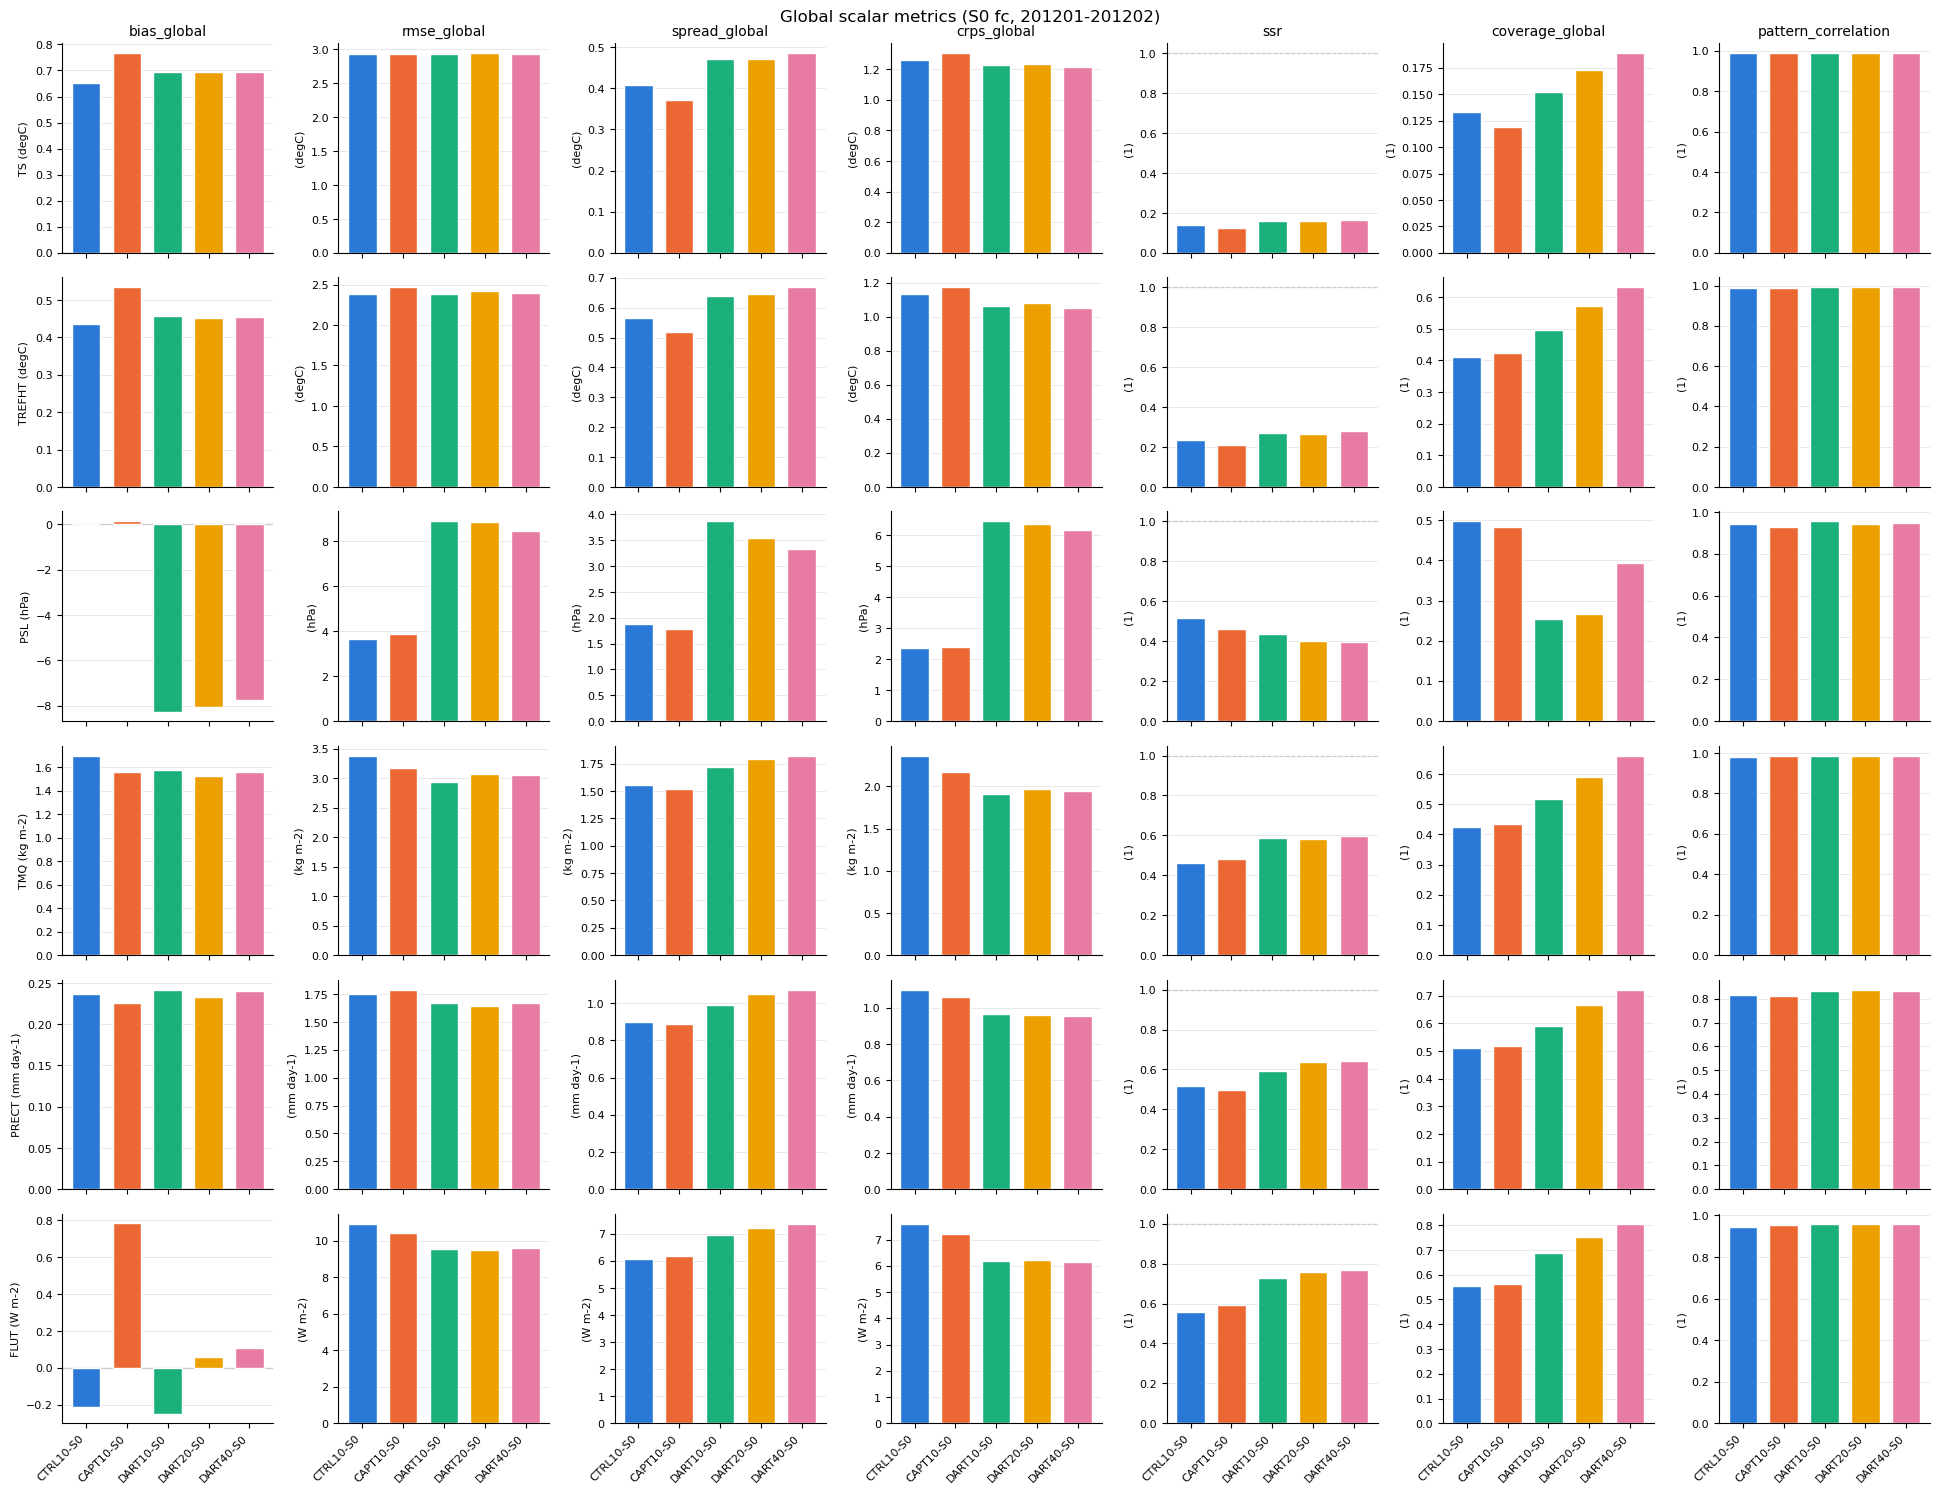

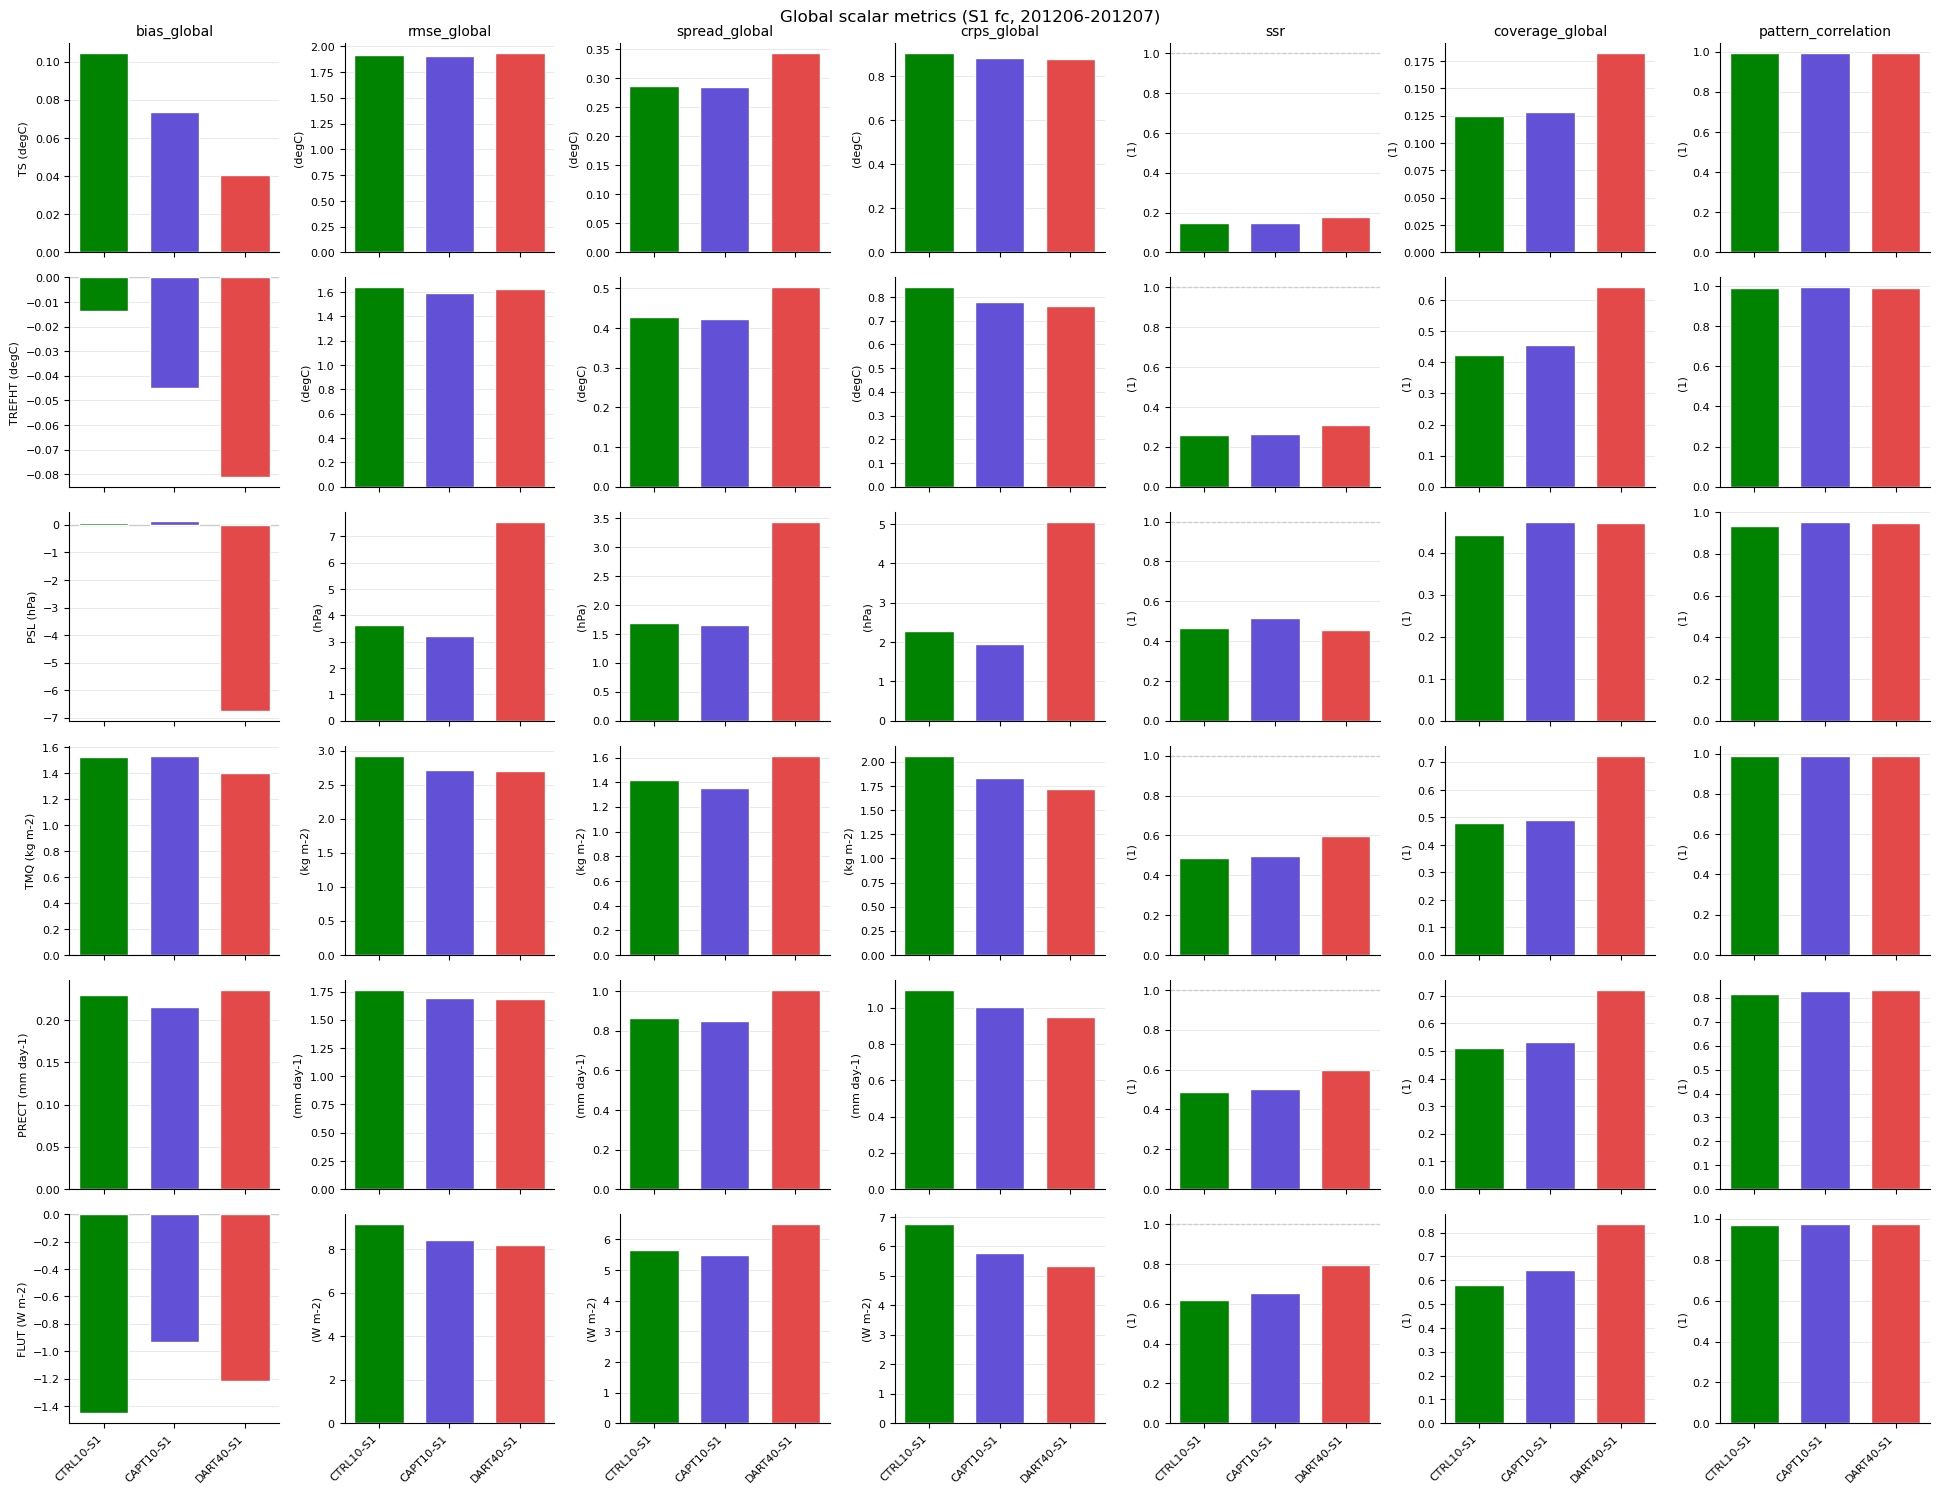

In [5]:
# One figure per case; experiments keep the same color in every figure.
colors = experiment_colors(summary["experiment"])
for season, table in summary.groupby("season", sort=False):
    period = table["period"].iloc[0]
    fig = plot_scalar_metrics(
        table, plot_metrics, variables=variables, colors=colors,
        title=f"Global scalar metrics ({season} {run_segment}, {period})",
    )
    output = figure_dir / f"scalar_metrics_{season}_{run_segment}.png"
    fig.savefig(output, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {output}")
    if not show:
        plt.close(fig)

## 6. Rank histograms

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_model_evaluation/TS_rank_histogram_S0_fc.png
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_model_evaluation/TREFHT_rank_histogram_S0_fc.png
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_model_evaluation/PSL_rank_histogram_S0_fc.png
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_model_evaluation/TMQ_rank_histogram_S0_fc.png
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_model_evaluation/PRECT_rank_histogram_S0_fc.png
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_model_evaluation/FLUT_rank_histogram_S0_fc.png
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_model_evaluation/TS_rank_histogram_S1_fc.png
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_model_evaluation/TREFHT_rank_histogram_S1_fc.png
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/fi

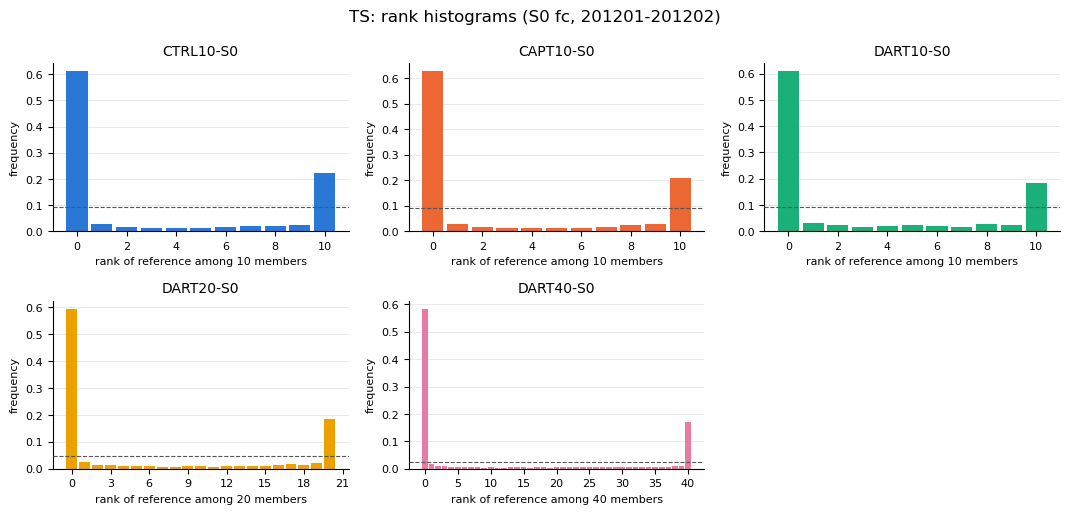

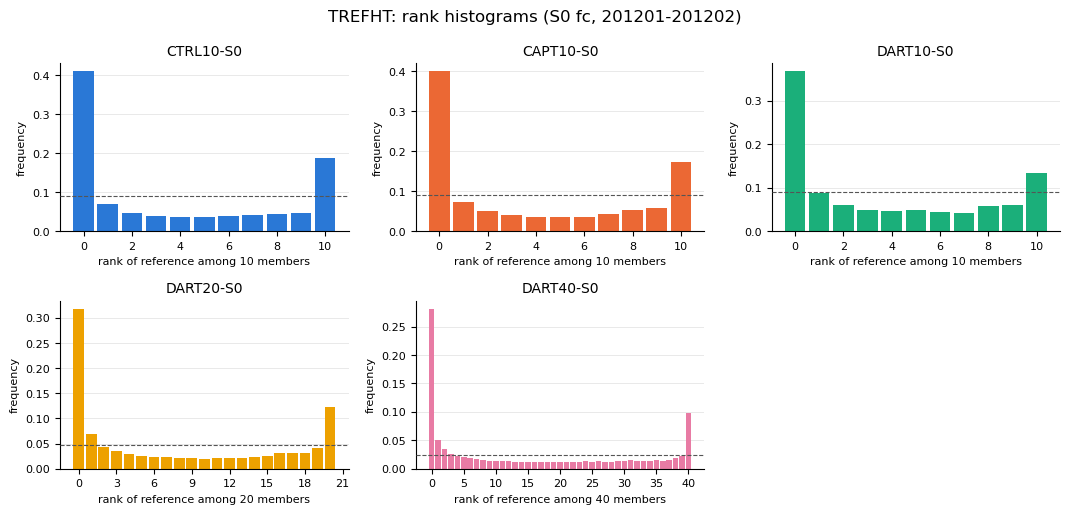

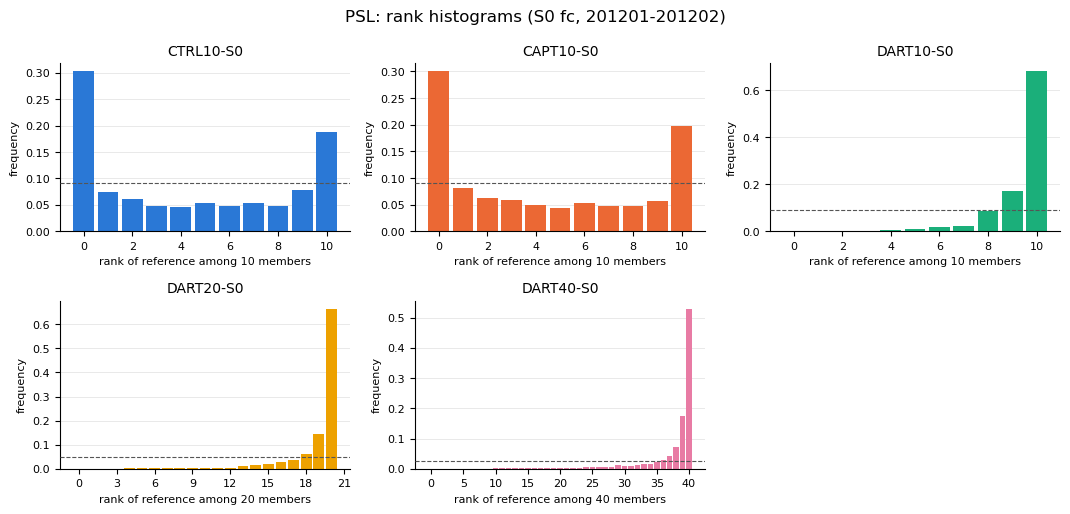

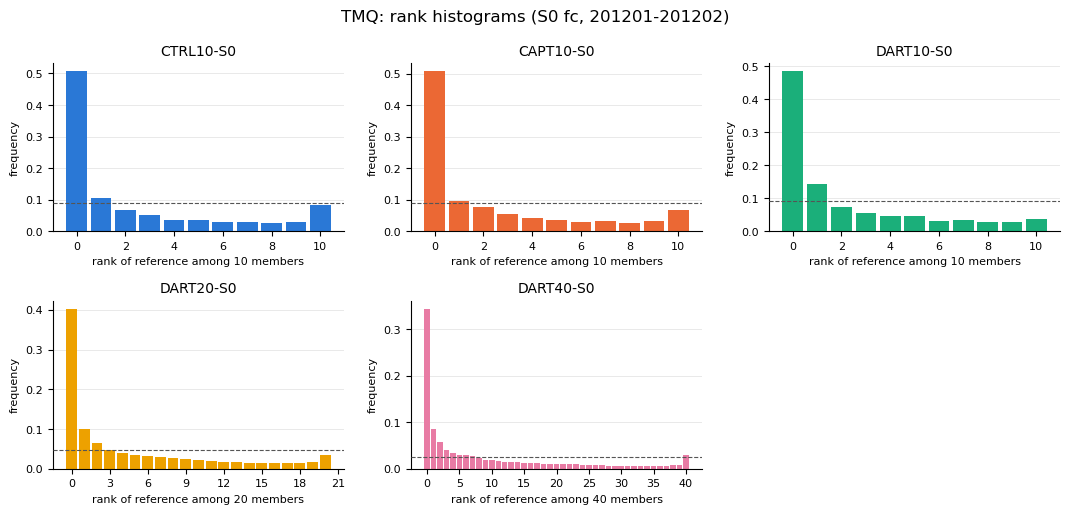

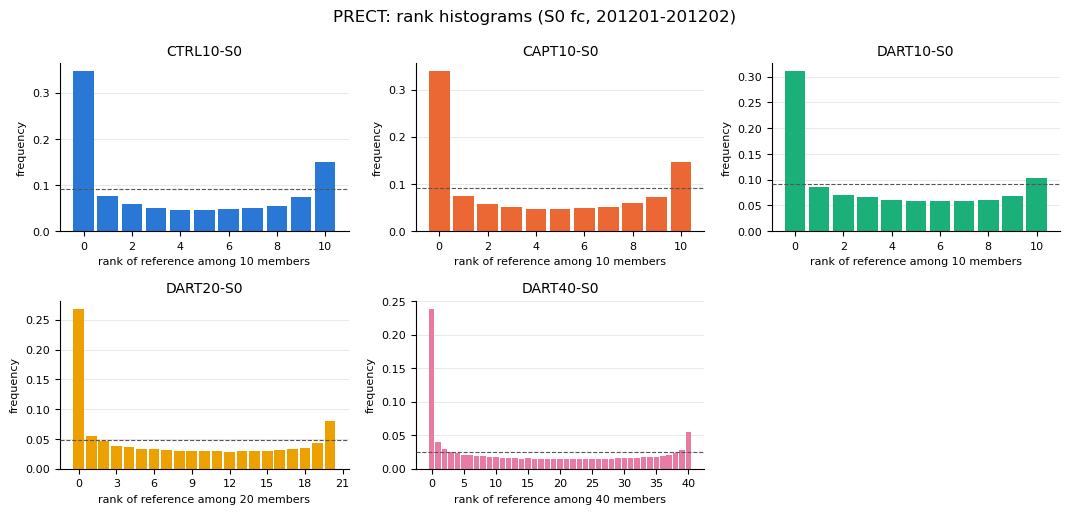

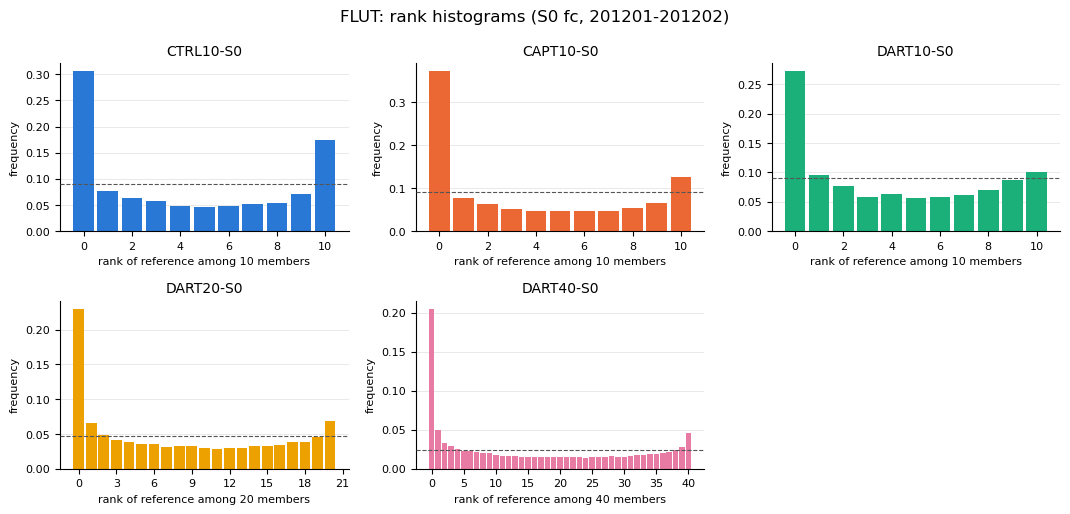

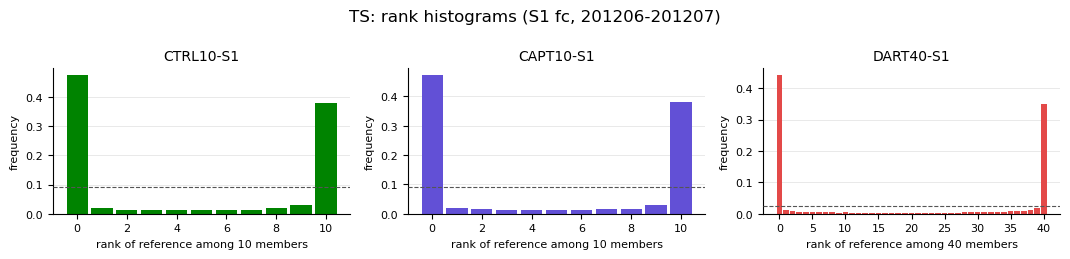

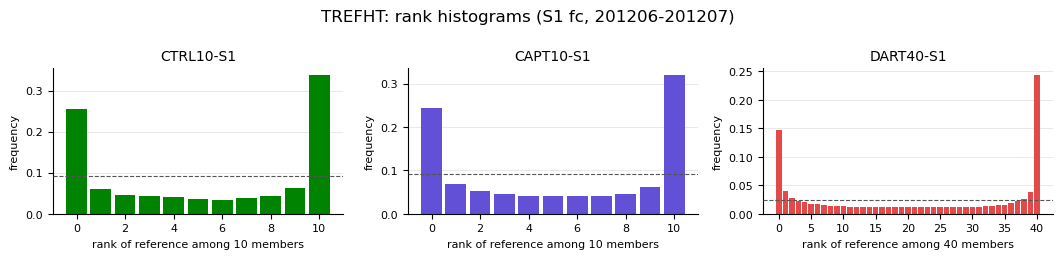

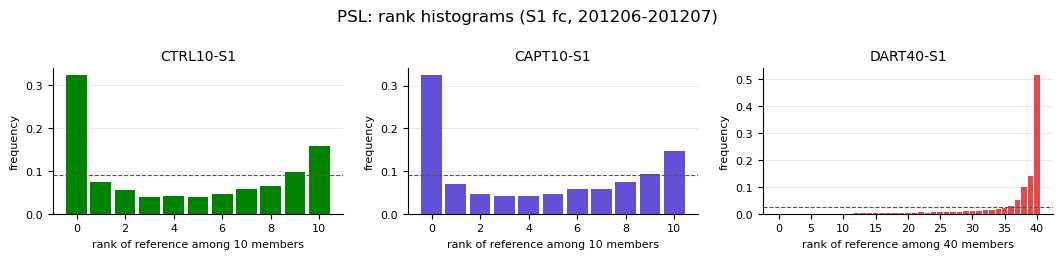

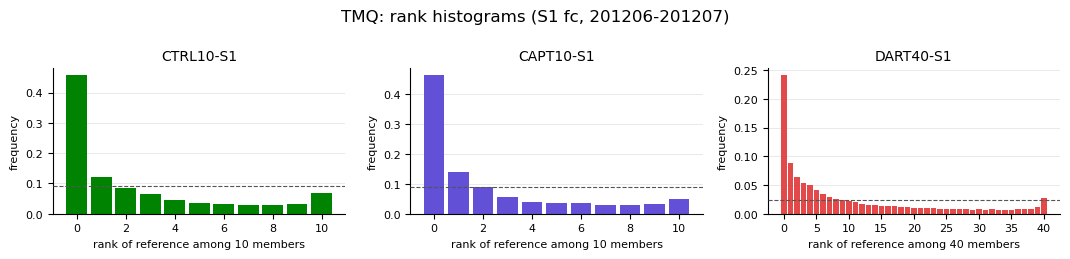

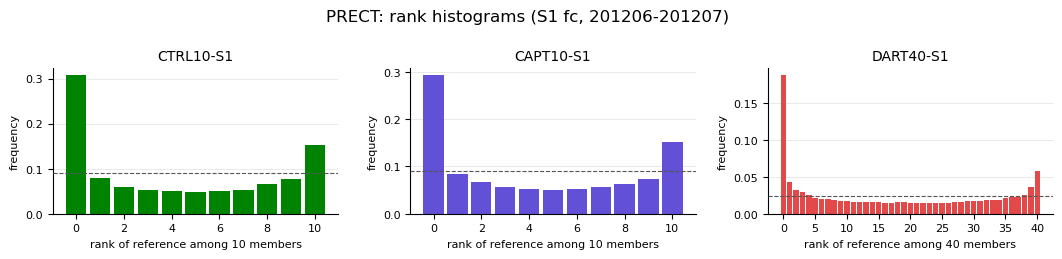

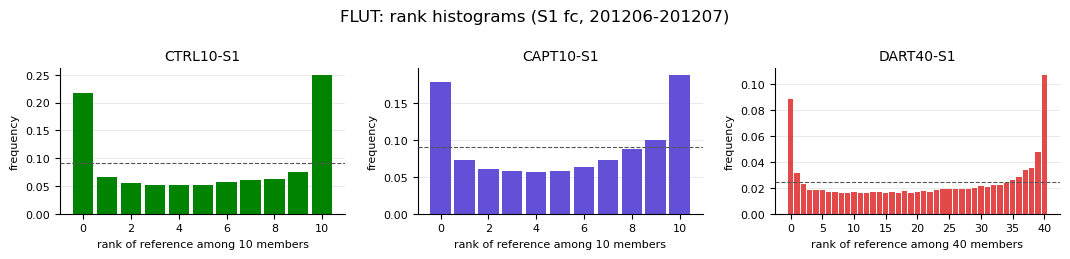

In [6]:
# A flat histogram indicates a well-dispersed ensemble; a U shape indicates under-dispersion.
if include_rank_histogram:
    for season, by_variable in results.items():
        registry = registries[season]
        for variable, datasets in by_variable.items():
            period = registry[next(iter(datasets))]["period"]
            fig = plot_rank_histograms(
                datasets, variable, colors=colors,
                label_map={name: registry[name]["label"] for name in datasets},
                title=f"{variable}: rank histograms ({season} {run_segment}, {period})",
            )
            output = figure_dir / f"{variable}_rank_histogram_{season}_{run_segment}.png"
            fig.savefig(output, dpi=FIGURE_DPI, bbox_inches="tight")
            print(f"[FIGURE] {output}")
            if not show:
                plt.close(fig)

## Notes: scalar metrics

| Metric | Definition |
|---|---|
| `model_global_mean`, `reference_global_mean` | global mean of the time-mean ensemble mean / reference |
| `model_rms`, `reference_rms` | spatial standard deviation of those climatologies |
| `rmse_global` | spatial RMSE of the ensemble-mean climatology against the reference |
| `pattern_correlation` | spatial correlation of the climatology anomalies |
| `bias_global`, `spread_global`, `crps_global`, `coverage_global` | global means of the corresponding maps |
| `ssr` | spread-skill ratio, `spread_global / rmse_global` (1 = well dispersed) |
| `bias_squared`, `spread_squared`, `mse`, `sem` | error-decomposition terms; `sem` = spread / sqrt(members) |
| `rank_histogram` | frequency of the reference's rank among the members over all valid samples |

Atmosphere variables: `FLUT` (CERES-OAFlux), `PRECT` (GPCP), `TMQ`, `TS`, `TREFHT`, and `PSL` (ERA5).

Caches: `<experiment>_<variable>_<period>_scalar_metrics.nc`; table: `scalar_metrics_summary_<run_segment>.csv`.